# Cross-validation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/02-data-preparation/cross-validation/cross-validation-notebook.ipynb)

Companion notebook for the *Cross-validation* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the Breast Cancer Wisconsin data (569 tumors, 30 measurements, malignant or benign).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import model_selection
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FOLD_COUNT = 5
NEIGHBOR_CHOICES = range(1, 32, 2)

X, y = load_breast_cancer(return_X_y=True)
model = make_pipeline(StandardScaler(), LogisticRegression())

## 1. k-fold cross-validation

Cut the shuffled rows into $k$ folds $F_1, \dots, F_k$. Train on $k-1$ folds, score on the one
left out, and repeat for every fold. The estimate is the average
$\text{CV}_{(k)} = \frac{1}{k}\sum_{m} s_m$.

In [2]:
class KFold:
    """Cut the row numbers into k folds; each fold is the test part once."""

    def __init__(self, n_splits=5, shuffle=False, random_state=None):
        self.n_splits, self.shuffle, self.random_state = n_splits, shuffle, random_state

    def split(self, X, y=None):
        rows = np.arange(len(X))
        if self.shuffle:
            rows = np.random.default_rng(self.random_state).permutation(rows)
        for test_rows in np.array_split(rows, self.n_splits):
            yield np.setdiff1d(rows, test_rows), test_rows


def cross_val_score(estimator, X, y, cv=5):
    """Train a fresh copy of the model on each training part and score it on the fold left out."""
    folds = KFold(cv) if isinstance(cv, int) else cv
    return np.array([clone(estimator).fit(X[train_rows], y[train_rows]).score(X[test_rows], y[test_rows])
                     for train_rows, test_rows in folds.split(X, y)])


fold_scores = cross_val_score(model, X, y, cv=KFold(FOLD_COUNT, shuffle=True, random_state=RANDOM_STATE))
print("fold scores:", np.round(fold_scores, 3))
print(f"CV estimate {fold_scores.mean():.3f}, spread {fold_scores.std():.3f}")

fold scores: [0.965 0.991 0.965 0.974 0.991]
CV estimate 0.977, spread 0.012


Without shuffling, both `KFold` classes cut the rows in the same places:

In [3]:
same_cuts = all(np.array_equal(ours, theirs) for (_, ours), (_, theirs)
                in zip(KFold(FOLD_COUNT).split(X), model_selection.KFold(FOLD_COUNT).split(X)))
print("same folds:", same_cuts)

same folds: True


In [4]:
same_folds = list(KFold(FOLD_COUNT, shuffle=True, random_state=RANDOM_STATE).split(X))
library_scores = model_selection.cross_val_score(model, X, y, cv=same_folds)
print("same scores on the same folds:", np.allclose(fold_scores, library_scores))

same scores on the same folds: True


In practice scikit-learn makes the folds itself:

In [5]:
folds = model_selection.StratifiedKFold(FOLD_COUNT, shuffle=True, random_state=RANDOM_STATE)
scores = model_selection.cross_val_score(model, X, y, cv=folds)
print(f"CV estimate {scores.mean():.3f} ± {scores.std():.3f}")

CV estimate 0.974 ± 0.017


`StratifiedKFold` builds the folds class by class, so every fold keeps the share of malignant tumors.

## 2. Choosing a setting

Try each value of a setting and keep the one with the best cross-validated score:
$\hat{\theta} = \arg\max_\theta \text{CV}_{(k)}(\theta)$. Here the setting is the number of neighbors in k-nearest neighbors.

best number of neighbors: 9


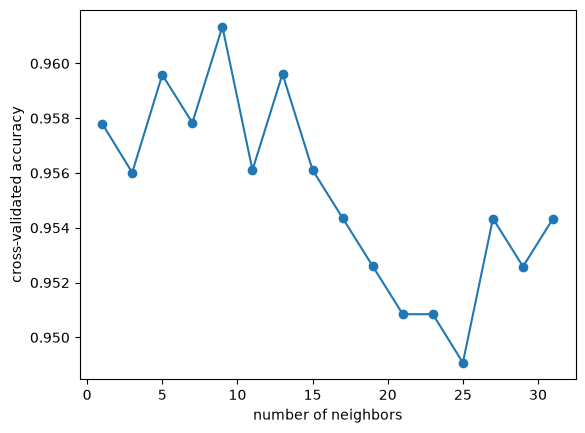

In [6]:
cv_accuracy = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X, y, cv=FOLD_COUNT).mean()
               for k in NEIGHBOR_CHOICES]
best_by_hand = list(NEIGHBOR_CHOICES)[int(np.argmax(cv_accuracy))]
print("best number of neighbors:", best_by_hand)

plt.plot(list(NEIGHBOR_CHOICES), cv_accuracy, marker="o")
plt.xlabel("number of neighbors")
plt.ylabel("cross-validated accuracy")
plt.show()

In [7]:
search = model_selection.GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                                      {"kneighborsclassifier__n_neighbors": list(NEIGHBOR_CHOICES)},
                                      cv=model_selection.KFold(FOLD_COUNT))
search.fit(X, y)
print("same choice:", search.best_params_["kneighborsclassifier__n_neighbors"] == best_by_hand)

same choice: True


## 3. The honest protocol

Keep a test set aside, choose the setting with cross-validation on the training part only,
and score the final model once on the test set.

In [8]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print("chosen:", search.best_params_, f"| test accuracy {search.score(X_test, y_test):.3f}")

chosen: {'kneighborsclassifier__n_neighbors': 7} | test accuracy 0.974


## Exercises

1. Repeat section 1 with $k = 2$ and $k = 10$. How do the average and the spread change?
2. Use `LeaveOneOut()` as `cv` in `cross_val_score`. How many models does it train?
3. Write the stratified folds by hand: split the rows of each class into $k$ parts and join them.